<a href="https://colab.research.google.com/github/Gamerisbackill/pbl-collage-/blob/main/SmartMach.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Shape of dataset (rows, columns): (10000, 14)

First 5 rows:
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                    1408         40.0                9                0    0   

   HDF  PWF  OSF  

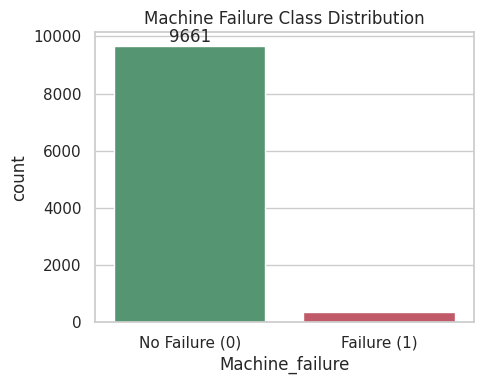

Failure rate: 3.39%  (data is imbalanced)


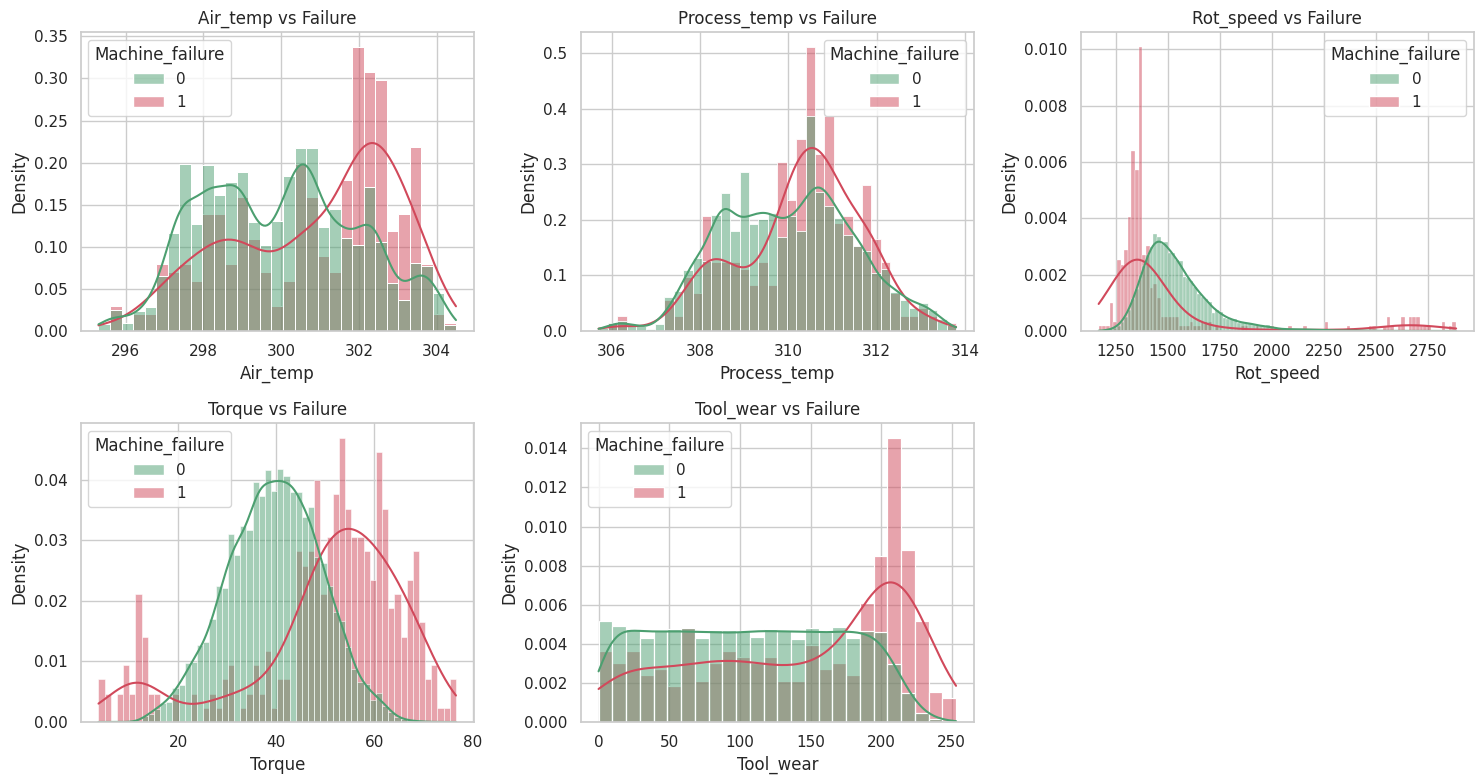

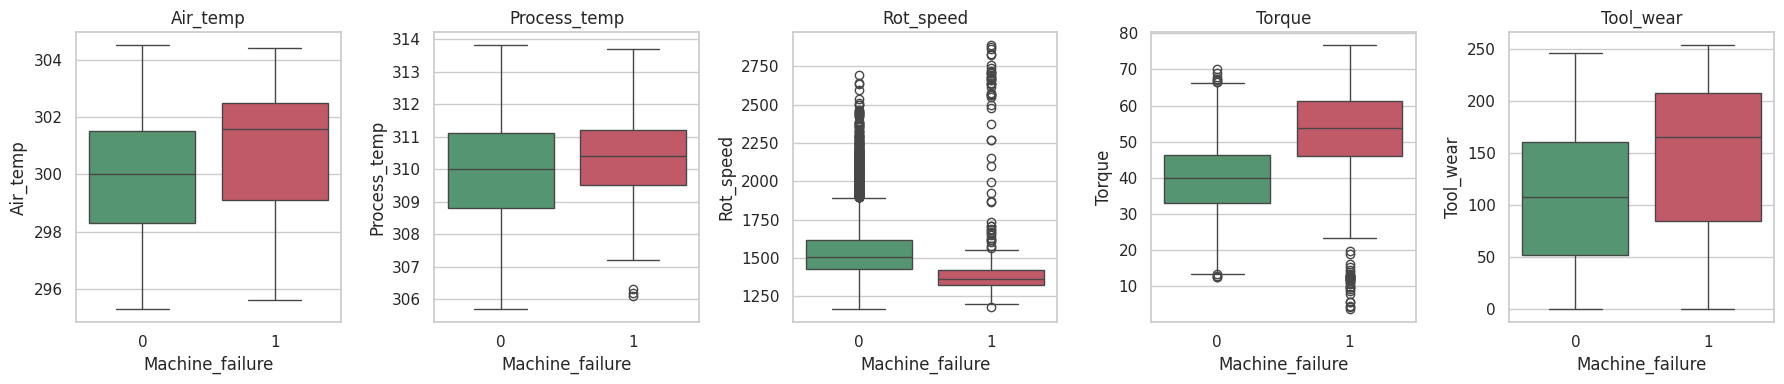


Failure rate (%) by machine type:
 L (Low)       3.92
M (Medium)    2.77
H (High)      2.09
Name: Machine_failure, dtype: float64


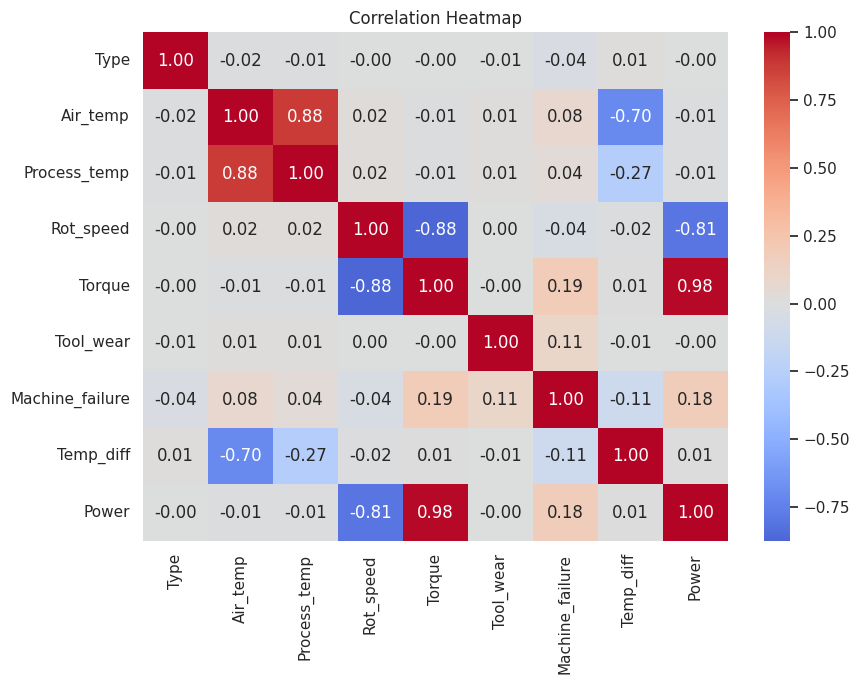


Correlation of each feature with Machine_failure:
Torque          0.191
Power           0.176
Tool_wear       0.105
Air_temp        0.083
Process_temp    0.036
Type           -0.037
Rot_speed      -0.044
Temp_diff      -0.112
Name: Machine_failure, dtype: float64
Training rows: 8000 | Testing rows: 2000
Failures in train: 271 | Failures in test: 68
Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest
Trained: SVM
Trained: KNN

=== MODEL COMPARISON (test set) ===
                     Accuracy  Precision  Recall  F1-score
Model                                                     
Random Forest          0.9875     0.9388  0.6765    0.7863
Decision Tree          0.9590     0.4470  0.8676    0.5900
KNN                    0.9760     0.8846  0.3382    0.4894
SVM                    0.9235     0.2967  0.9118    0.4477
Logistic Regression    0.8575     0.1761  0.8676    0.2928

--- Logistic Regression ---
              precision    recall  f1-score   support

  No Failure 

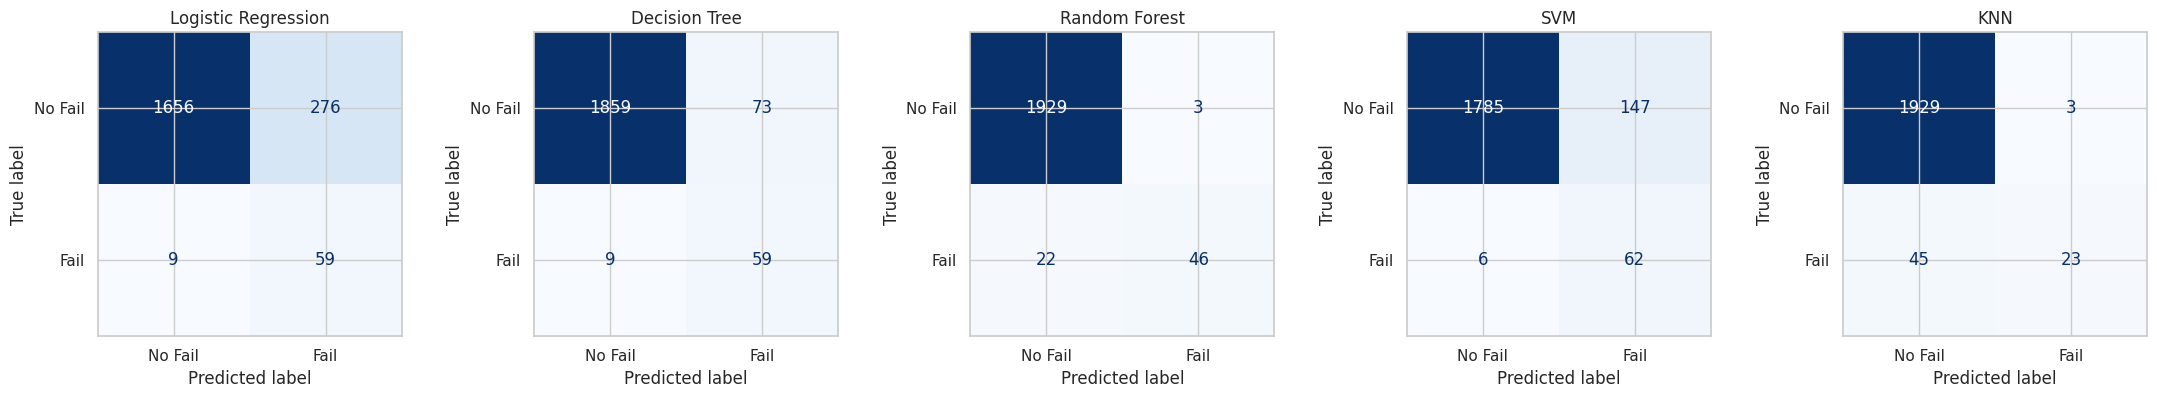

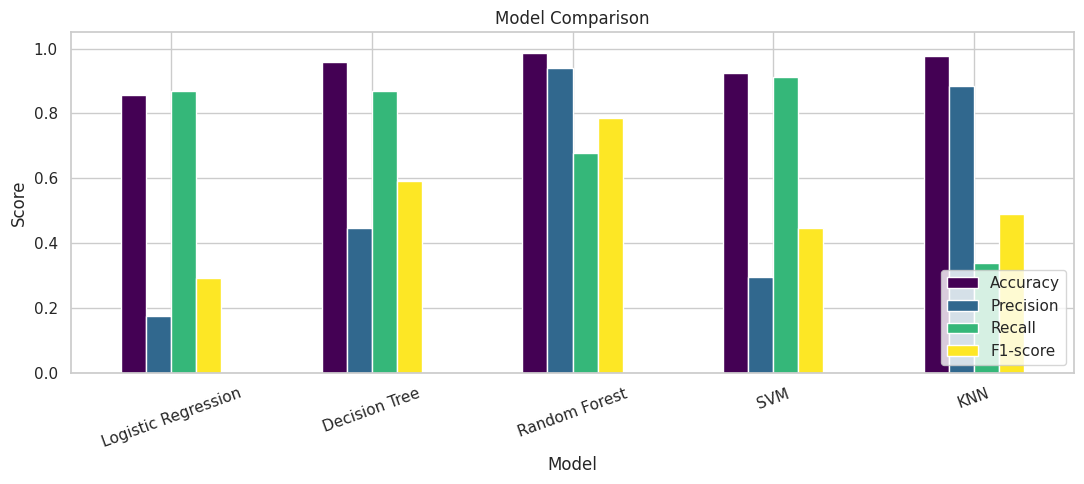


Best model: Random Forest
Accuracy     0.9875
Precision    0.9388
Recall       0.6765
F1-score     0.7863
Name: Random Forest, dtype: float64

Feature importance for Random Forest (drop in F1 when shuffled):
Rot_speed       0.4497
Torque          0.3802
Temp_diff       0.2781
Power           0.2651
Air_temp        0.1978
Tool_wear       0.1354
Type            0.0360
Process_temp    0.0310
dtype: float64


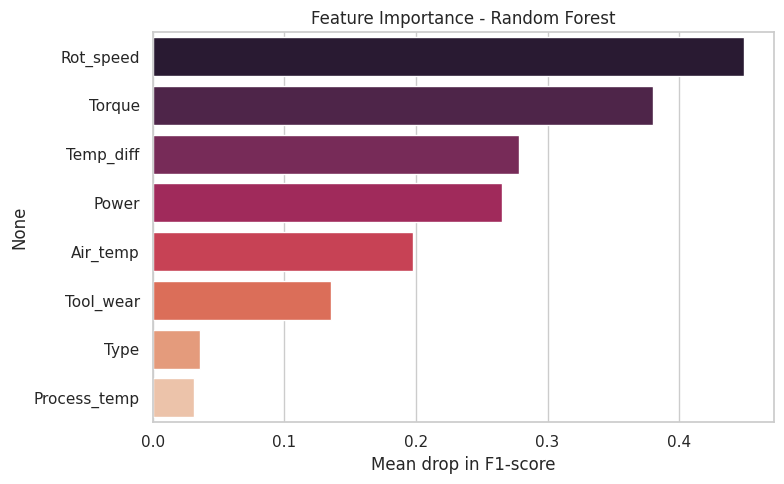


Random Forest built-in importance:
 Torque          0.2026
Rot_speed       0.2008
Power           0.1976
Tool_wear       0.1937
Temp_diff       0.0874
Air_temp        0.0653
Process_temp    0.0405
Type            0.0122
dtype: float64

=== SAMPLE PREDICTIONS ===
Healthy machine: No failure expected | Probability = 0.00% | Risk = Low Risk
Heavily worn tool: FAILURE LIKELY | Probability = 74.50% | Risk = High Risk
Overstrain (high load): FAILURE LIKELY | Probability = 81.00% | Risk = High Risk
Low speed / low heat diff: FAILURE LIKELY | Probability = 88.50% | Risk = High Risk

Risk levels over the test set:
 Low Risk       1939
High Risk        40
Medium Risk      21
Name: count, dtype: int64

=== User Input ===
Predict for a machine? (y/n): n

Saved best model (Random Forest) to smartmach_outputs/smartmach_best_model.joblib
To reload later: model = joblib.load(model_path)


In [2]:
# %% [markdown]
# # SmartMach – Machine Learning based Predictive Maintenance
# **Course:** Machine Learning Lab (24M15CA114) | **Program:** MCA 1st Year 1st Sem
# **Dataset:** AI4I 2020 Predictive Maintenance Dataset (UCI)
#
# Workflow (from the synopsis):
# Dataset Collection -> Data Preprocessing -> EDA & Feature Engineering ->
# Model Training -> Model Comparison -> Evaluation -> Failure/Risk Prediction
#
# Installation (only if a library is missing; Google Colab already has all of them):
#     pip install pandas numpy matplotlib seaborn scikit-learn joblib

# %% ============================================================
# SECTION 0: IMPORTS AND SETTINGS
# ===============================================================
import os
import io
import zipfile
import urllib.request
import warnings

import numpy as np                      # numerical operations
import pandas as pd                     # tables / dataframes
import matplotlib.pyplot as plt         # plotting
import seaborn as sns                   # nicer statistical plots
import joblib                           # saving the final model

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42            # fixed seed so results are repeatable
TEST_SIZE = 0.20             # 80% training / 20% testing
OUTPUT_DIR = "smartmach_outputs"   # folder where plots and the model are saved
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Risk-level thresholds on predicted failure probability.
# NOTE: the synopsis does not give these numbers - they are an ASSUMPTION; change if your guide says otherwise.
LOW_RISK_MAX = 0.30          # probability < 0.30          -> Low Risk
MEDIUM_RISK_MAX = 0.60       # 0.30 <= probability < 0.60  -> Medium Risk, else High Risk

DATA_FILE = "ai4i2020.csv"   # local file name of the dataset
DATA_URL = ("https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip")


def show_and_save(fig_name):
    """Save the current matplotlib figure into OUTPUT_DIR and display it."""
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, fig_name), dpi=150)
    plt.show()


# %% ============================================================
# SECTION 1: DATASET COLLECTION
# Objective 1: "collect ... industrial machine sensor data"
# ===============================================================
def load_dataset():
    """Load AI4I 2020 data: (1) local csv, (2) download from UCI, (3) Colab upload."""
    # 1) Use the local file if it already exists
    if os.path.exists(DATA_FILE):
        print(f"Loaded local file: {DATA_FILE}")
        return pd.read_csv(DATA_FILE)

    # 2) Try to download the zip from the UCI repository
    try:
        print("Downloading dataset from UCI ...")
        with urllib.request.urlopen(DATA_URL, timeout=60) as response:
            zipped = zipfile.ZipFile(io.BytesIO(response.read()))
        csv_name = [n for n in zipped.namelist() if n.endswith(".csv")][0]
        with zipped.open(csv_name) as f:
            df_ = pd.read_csv(f)
        df_.to_csv(DATA_FILE, index=False)      # cache it for next time
        return df_
    except Exception as err:
        print(f"Download failed ({err}).")

    # 3) Last option: ask the user to upload the csv (works in Google Colab)
    try:
        from google.colab import files
        print("Please upload ai4i2020.csv ...")
        uploaded = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(uploaded.values()))))
    except ImportError:
        raise FileNotFoundError(
            "Dataset not found. Download 'ai4i2020.csv' from the UCI repository "
            "(AI4I 2020 Predictive Maintenance Dataset) and put it next to this script.")


df = load_dataset()
print("\nShape of dataset (rows, columns):", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nColumn info:")
df.info()


# %% ============================================================
# SECTION 2: DATA PREPROCESSING
# Objective 1: handle missing/duplicate values, encode categorical data, scale features
# ===============================================================
# 2.1 Rename columns: remove brackets/spaces so names are easy to use
df = df.rename(columns={
    "Air temperature [K]": "Air_temp",
    "Process temperature [K]": "Process_temp",
    "Rotational speed [rpm]": "Rot_speed",
    "Torque [Nm]": "Torque",
    "Tool wear [min]": "Tool_wear",
    "Machine failure": "Machine_failure",
})

# 2.2 Missing values
print("Missing values per column:\n", df.isnull().sum())
before = len(df)
df = df.dropna()                       # remove rows with any missing value (none expected)
print(f"Rows removed due to missing values: {before - len(df)}")

# 2.3 Duplicate values (UDI / Product ID are identifiers, so ignore them while checking)
feature_cols_for_dup = ["Type", "Air_temp", "Process_temp", "Rot_speed", "Torque",
                        "Tool_wear", "Machine_failure"]
dups = df.duplicated(subset=feature_cols_for_dup).sum()
print(f"Duplicate rows found: {dups}")
df = df.drop_duplicates(subset=feature_cols_for_dup).reset_index(drop=True)

# 2.4 Drop columns that must NOT be used for prediction
#     - UDI, Product ID : only identifiers, carry no information
#     - TWF, HDF, PWF, OSF, RNF : individual failure-mode labels. They directly
#       decide 'Machine_failure', so using them as inputs would be data leakage.
drop_cols = [c for c in ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"] if c in df.columns]
df = df.drop(columns=drop_cols)
print("Dropped columns:", drop_cols)

# 2.5 Encode categorical data: Type (L, M, H) -> numbers.
#     Type is ordered (Low < Medium < High quality variant), so ordinal encoding is suitable.
type_mapping = {"L": 0, "M": 1, "H": 2}
df["Type"] = df["Type"].map(type_mapping)
print("Rows with unknown 'Type' value:", df["Type"].isnull().sum())
df = df.dropna(subset=["Type"])
df["Type"] = df["Type"].astype(int)

# (Scaling is done later inside a Pipeline so it is learnt on training data only.)
print("\nCleaned data:")
print(df.head())


# %% ============================================================
# SECTION 3: EXPLORATORY DATA ANALYSIS (EDA)
# Objective 2: "analyze factors associated with machine failure"
# ===============================================================
print("Statistical summary:\n", df.describe().T)

# 3.1 Class distribution (failure vs no failure)
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Machine_failure", data=df, palette=["#4C9F70", "#D1495B"])
ax.set_xticklabels(["No Failure (0)", "Failure (1)"])
ax.bar_label(ax.containers[0])
plt.title("Machine Failure Class Distribution")
show_and_save("01_class_distribution.png")
fail_pct = df["Machine_failure"].mean() * 100
print(f"Failure rate: {fail_pct:.2f}%  (data is imbalanced)")

# 3.2 Distribution of every sensor feature, split by failure / no failure
sensor_cols = ["Air_temp", "Process_temp", "Rot_speed", "Torque", "Tool_wear"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), sensor_cols):
    sns.histplot(data=df, x=col, hue="Machine_failure", kde=True, ax=ax,
                 palette=["#4C9F70", "#D1495B"], stat="density", common_norm=False)
    ax.set_title(f"{col} vs Failure")
axes.ravel()[-1].axis("off")           # 6th slot is unused
show_and_save("02_feature_distributions.png")

# 3.3 Boxplots to see how failed machines differ from healthy ones
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, sensor_cols):
    sns.boxplot(x="Machine_failure", y=col, data=df, ax=ax, palette=["#4C9F70", "#D1495B"])
    ax.set_title(col)
show_and_save("03_boxplots.png")

# 3.4 Failure rate by machine Type
type_rate = df.groupby("Type")["Machine_failure"].mean().mul(100)
type_rate.index = ["L (Low)", "M (Medium)", "H (High)"][:len(type_rate)]
print("\nFailure rate (%) by machine type:\n", type_rate.round(2))


# %% ============================================================
# SECTION 4: FEATURE ENGINEERING
# Workflow step: "EDA & Feature Engineering"
# ===============================================================
# Two physically meaningful features for this kind of data:
#  - Temp_diff : process temperature - air temperature (heat dissipation)
#  - Power     : torque x rotational speed in rad/s (mechanical power in watts)
df["Temp_diff"] = df["Process_temp"] - df["Air_temp"]
df["Power"] = df["Torque"] * df["Rot_speed"] * 2 * np.pi / 60

# 3.5 Correlation heatmap (done after engineering so new features are included)
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
show_and_save("04_correlation_heatmap.png")

print("\nCorrelation of each feature with Machine_failure:")
print(df.corr()["Machine_failure"].drop("Machine_failure").sort_values(ascending=False).round(3))


# %% ============================================================
# SECTION 5: TRAIN / TEST SPLIT
# ===============================================================
FEATURES = ["Type", "Air_temp", "Process_temp", "Rot_speed", "Torque",
            "Tool_wear", "Temp_diff", "Power"]
X = df[FEATURES]
y = df["Machine_failure"]

# 'stratify=y' keeps the same failure percentage in both train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
print(f"Training rows: {len(X_train)} | Testing rows: {len(X_test)}")
print(f"Failures in train: {y_train.sum()} | Failures in test: {y_test.sum()}")


# %% ============================================================
# SECTION 6: MODEL TRAINING
# Objective 3: develop multiple ML models (the 5 listed in the synopsis)
# ===============================================================
# Each model is wrapped in a Pipeline: StandardScaler (feature scaling) -> classifier.
# ASSUMPTION: failures are only ~3% of rows, so class_weight='balanced' is used where
# supported (KNN has no such option) - otherwise models would just predict "no failure".
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000,
                                              random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", max_depth=6,
                                            random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(class_weight="balanced", n_estimators=200,
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "SVM": SVC(class_weight="balanced", probability=True, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
}

trained = {}   # name -> fitted pipeline
for name, clf in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", clf)])
    pipe.fit(X_train, y_train)           # learn scaling + model from training data only
    trained[name] = pipe
    print(f"Trained: {name}")


# %% ============================================================
# SECTION 7: MODEL EVALUATION AND COMPARISON
# Objective 4: Accuracy, Precision, Recall, F1-score, Confusion Matrix
# ===============================================================
# Precision / Recall / F1 are reported for the FAILURE class (label 1),
# because that is the class we care about detecting.
rows, predictions = [], {}
for name, pipe in trained.items():
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
print("\n=== MODEL COMPARISON (test set) ===")
print(results.sort_values("F1-score", ascending=False))

# 7.1 Classification report of each model
for name, y_pred in predictions.items():
    print(f"\n--- {name} ---")
    print(classification_report(y_test, y_pred, target_names=["No Failure", "Failure"], zero_division=0))

# 7.2 Confusion matrix of each model
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["No Fail", "Fail"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
show_and_save("05_confusion_matrices.png")

# 7.3 Bar chart comparing the metrics of all models
results.plot(kind="bar", figsize=(11, 5), colormap="viridis")
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
show_and_save("06_model_comparison.png")


# %% ============================================================
# SECTION 8: BEST MODEL SELECTION
# "The best-performing model will be selected based on suitable evaluation metrics"
# ===============================================================
# Accuracy is misleading on imbalanced data (always predicting "no failure" gives ~97%),
# so the best model is chosen by F1-score of the failure class.
best_name = results["F1-score"].idxmax()
best_model = trained[best_name]
print(f"\nBest model: {best_name}")
print(results.loc[best_name])


# %% ============================================================
# SECTION 9: IMPORTANT PARAMETERS INFLUENCING FAILURE
# Objective 5: identify important parameters
# ===============================================================
# Permutation importance works for ANY model: it shuffles one feature at a time and
# measures how much the F1-score drops. A bigger drop = more important feature.
perm = permutation_importance(best_model, X_test, y_test, scoring="f1",
                              n_repeats=10, random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
print(f"\nFeature importance for {best_name} (drop in F1 when shuffled):")
print(importance.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index, palette="rocket")
plt.title(f"Feature Importance - {best_name}")
plt.xlabel("Mean drop in F1-score")
show_and_save("07_feature_importance.png")

# Random Forest also has its own built-in importance - shown for reference
rf_imp = pd.Series(trained["Random Forest"].named_steps["model"].feature_importances_,
                   index=FEATURES).sort_values(ascending=False)
print("\nRandom Forest built-in importance:\n", rf_imp.round(4))


# %% ============================================================
# SECTION 10: FAILURE AND RISK PREDICTION (Low / Medium / High)
# Objective 6: classify machine conditions; "final system will accept machine
# operating parameters as input and provide a failure prediction and risk level"
# ===============================================================
def risk_level(prob):
    """Convert failure probability into Low / Medium / High risk (thresholds set in Section 0)."""
    if prob < LOW_RISK_MAX:
        return "Low Risk"
    if prob < MEDIUM_RISK_MAX:
        return "Medium Risk"
    return "High Risk"


def predict_machine(machine_type, air_temp, process_temp, rot_speed, torque, tool_wear, model=best_model):
    """Predict failure and risk level for one machine. Raises ValueError on invalid input."""
    machine_type = str(machine_type).strip().upper()
    if machine_type not in type_mapping:
        raise ValueError("Type must be L, M or H.")
    try:
        air_temp, process_temp, rot_speed, torque, tool_wear = map(
            float, (air_temp, process_temp, rot_speed, torque, tool_wear))
    except (TypeError, ValueError):
        raise ValueError("All sensor values must be numbers.")
    if min(air_temp, process_temp, rot_speed, torque, tool_wear) < 0:
        raise ValueError("Sensor values cannot be negative.")
    if rot_speed == 0:
        raise ValueError("Rotational speed must be greater than 0.")

    # Build one row with exactly the same features/order used in training
    row = pd.DataFrame([{
        "Type": type_mapping[machine_type],
        "Air_temp": air_temp, "Process_temp": process_temp,
        "Rot_speed": rot_speed, "Torque": torque, "Tool_wear": tool_wear,
        "Temp_diff": process_temp - air_temp,
        "Power": torque * rot_speed * 2 * np.pi / 60,
    }])[FEATURES]

    prob = model.predict_proba(row)[0, 1]          # probability of failure
    return {"failure_predicted": bool(prob >= 0.5),
            "failure_probability": round(float(prob), 4),
            "risk_level": risk_level(prob)}


def show_prediction(label, result):
    """Print a prediction result in a readable way."""
    status = "FAILURE LIKELY" if result["failure_predicted"] else "No failure expected"
    print(f"{label}: {status} | Probability = {result['failure_probability']:.2%} "
          f"| Risk = {result['risk_level']}")


# 10.1 Demo with sample machines
print("\n=== SAMPLE PREDICTIONS ===")
samples = {
    "Healthy machine":      ("M", 298.1, 308.6, 1551, 42.8, 0),
    "Heavily worn tool":    ("L", 298.9, 309.1, 1500, 60.0, 240),
    "Overstrain (high load)": ("L", 298.0, 308.5, 1380, 65.0, 220),
    "Low speed / low heat diff": ("M", 302.0, 310.2, 1290, 50.0, 100),
}
for label, params in samples.items():
    show_prediction(label, predict_machine(*params))

# 10.2 Risk-level distribution over the whole test set
test_probs = best_model.predict_proba(X_test)[:, 1]
test_risk = pd.Series([risk_level(p) for p in test_probs])
print("\nRisk levels over the test set:\n", test_risk.value_counts())

# 10.3 Interactive input (user types values). Set to False to skip.
RUN_INTERACTIVE = True

if RUN_INTERACTIVE:
    print("\n=== User Input ===")
    while True:
        go = input("Predict for a machine? (y/n): ").strip().lower()
        if go != "y":
            break
        try:
            result = predict_machine(
                input("Type (L/M/H): "),
                input("Air temperature [K] (e.g. 300): "),
                input("Process temperature [K] (e.g. 310): "),
                input("Rotational speed [rpm] (e.g. 1500): "),
                input("Torque [Nm] (e.g. 40): "),
                input("Tool wear [min] (e.g. 100): "))
            show_prediction("Result", result)
        except ValueError as err:           # invalid input is reported, not crashed
            print("Invalid input:", err)


# %% ============================================================
# SECTION 11: SAVE THE FINAL MODEL
# ===============================================================
model_path = os.path.join(OUTPUT_DIR, "smartmach_best_model.joblib")
joblib.dump(best_model, model_path)
results.to_csv(os.path.join(OUTPUT_DIR, "model_comparison.csv"))
print(f"\nSaved best model ({best_name}) to {model_path}")
print("To reload later: model = joblib.load(model_path)")